Praktikum 2 - FAISS IndexFlatL2 (exact) vs IndexIVFPQ (approx).

Variasi: metrik L2 vs Inner Product (cosine), 1.000 vs 1.000.000 data, 2D vs 5D.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("p2_faiss_ivfpq.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-ann-approximate-nearest-neighbors\praktikum-2


In [2]:
from pathlib import Path
import csv
import os
import time
import warnings

import numpy as np
import faiss
import matplotlib

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
OUT = Path(__file__).parent / "output"
OUT.mkdir(exist_ok=True)
K = 3

In [3]:
def unit(A):
    return A / np.maximum(np.linalg.norm(A, axis=1, keepdims=True), 1e-12)

L2 N=   1000 d=2 | flat [258  17 971] dist [0.     0.0001 0.001 ] | ivfpq [258  17 971] dist [0.     0.0001 0.0011] | flat 0.022 ms  ivfpq 0.020 ms (build 31 ms) | recall=0.907
L2 N=   1000 d=5 | flat [812  34 550] dist [0.0314 0.0397 0.055 ] | ivfpq [812  34 550] dist [0.0309 0.0397 0.0549] | flat 0.004 ms  ivfpq 0.006 ms (build 28 ms) | recall=0.747


L2 N=1000000 d=2 | flat [600900 695075 587490] dist [0. 0. 0.] | ivfpq [600900 695075 587490] dist [0. 0. 0.] | flat 1.333 ms  ivfpq 0.026 ms (build 2908 ms) | recall=0.807


L2 N=1000000 d=5 | flat [ 85158 586716 687018] dist [0.0022 0.0026 0.0029] | ivfpq [ 85158 586716 687018] dist [0.0023 0.0024 0.0029] | flat 2.419 ms  ivfpq 0.041 ms (build 6329 ms) | recall=0.840
IP N=   1000 d=2 | flat [604 147 545] dist [1.     0.9999 0.9999] | ivfpq [604 400 147] dist [1.0012 1.0004 1.0002] | flat 0.002 ms  ivfpq 0.010 ms (build 13 ms) | recall=0.380
IP N=   1000 d=5 | flat [132 422 951] dist [0.9574 0.9486 0.918 ] | ivfpq [132 422 951] dist [0.9609 0.942  0.9176] | flat 0.004 ms  ivfpq 0.009 ms (build 30 ms) | recall=0.720


IP N=1000000 d=2 | flat [310459 233529 178822] dist [1. 1. 1.] | ivfpq [829399 255470 182567] dist [1.0001 1.0001 1.0001] | flat 1.003 ms  ivfpq 0.024 ms (build 2793 ms) | recall=0.007


IP N=1000000 d=5 | flat [709164 675568 192964] dist [0.9995 0.9984 0.9979] | ivfpq [192964 954371 119185] dist [0.9982 0.9978 0.9969] | flat 2.150 ms  ivfpq 0.039 ms (build 6372 ms) | recall=0.640



Catatan: IVFPQ memakai nprobe=1 dan 8 bit/subvektor -> jarak bersifat aproksimasi.


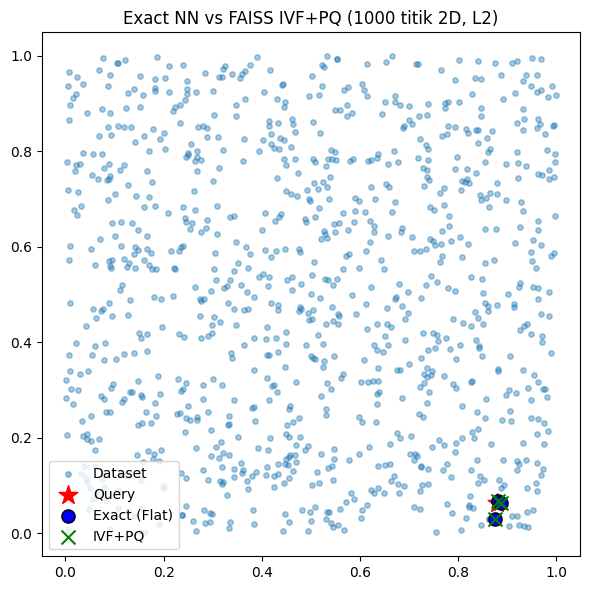

In [4]:
def run(n, d, metric, nlist, m, bits=8, nprobe=1):
    rng = np.random.default_rng(42)
    X = rng.random((n, d), dtype=np.float32)
    Q = rng.random((50, d), dtype=np.float32)
    if metric == "ip":
        X = rng.standard_normal((n, d), dtype=np.float32)  # data 2D [0,1) semua cosine ~1 -> tidak diskriminatif
        Q = rng.standard_normal((50, d), dtype=np.float32)
        X, Q = unit(X), unit(Q)
        mf = faiss.METRIC_INNER_PRODUCT
    else:
        mf = faiss.METRIC_L2

    flat = faiss.IndexFlat(d, mf)
    flat.add(X)
    t0 = time.perf_counter()
    D_f, I_f = flat.search(Q, K)
    t_flat = (time.perf_counter() - t0) / len(Q) * 1000

    t0 = time.perf_counter()
    ivfpq = faiss.IndexIVFPQ(faiss.IndexFlat(d, mf), d, nlist, m, bits, mf)
    fd, null = os.dup(2), os.open(os.devnull, os.O_WRONLY)  # redam warning kmeans faiss (stderr C++)
    os.dup2(null, 2)
    try:
        ivfpq.train(X)
    finally:
        os.dup2(fd, 2); os.close(null); os.close(fd)
    ivfpq.add(X)
    ivfpq.nprobe = nprobe
    build = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter()
    D_a, I_a = ivfpq.search(Q, K)
    t_a = (time.perf_counter() - t0) / len(Q) * 1000

    rec = float(np.mean([len(set(a) & set(b)) / K for a, b in zip(I_a, I_f)]))
    return dict(n=n, d=d, metric=metric, I_f=I_f, D_f=D_f, I_a=I_a, D_a=D_a,
                t_flat=t_flat, t_a=t_a, build=build, rec=rec, X=X, Q=Q)


rows, scalar_plot = [], None
for metric in ["l2", "ip"]:
    for n, nlist in [(1000, 10), (1_000_000, 100)]:
        for d in [2, 5]:
            r = run(n, d, metric, nlist, m=d)
            rows.append([metric, n, d, nlist, r["t_flat"], r["build"], r["t_a"],
                         round(r["t_flat"] / r["t_a"], 2), round(r["rec"], 3)])
            print(f"{metric.upper():2s} N={n:7d} d={d} | flat {r['I_f'][0]} dist {np.round(r['D_f'][0], 4)} "
                  f"| ivfpq {r['I_a'][0]} dist {np.round(r['D_a'][0], 4)} "
                  f"| flat {r['t_flat']:.3f} ms  ivfpq {r['t_a']:.3f} ms (build {r['build']:.0f} ms) "
                  f"| recall={r['rec']:.3f}")
            if n == 1000 and d == 2 and metric == "l2":
                scalar_plot = r

with open(OUT / "hasil_tabel.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["metrik", "jumlah_data", "dimensi", "nlist", "flat_ms", "build_ms", "ivfpq_ms", "speedup", "recall@3"])
    w.writerows(rows)

r = scalar_plot
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(r["X"][:, 0], r["X"][:, 1], alpha=0.4, s=15, label="Dataset")
ax.scatter(*r["Q"][0], c="red", marker="*", s=200, label="Query")
ax.scatter(*r["X"][r["I_f"][0]].T, c="blue", s=90, edgecolor="k", label="Exact (Flat)")
ax.scatter(*r["X"][r["I_a"][0]].T, c="green", marker="x", s=100, label="IVF+PQ")
ax.legend()
ax.set_title("Exact NN vs FAISS IVF+PQ (1000 titik 2D, L2)")
fig.tight_layout()
fig.savefig(OUT / "p2_flat_vs_ivfpq.png", dpi=120)

print("\nCatatan: IVFPQ memakai nprobe=1 dan 8 bit/subvektor -> jarak bersifat aproksimasi.")